# Semana 7: Challenge Keras 3: CIFAR-10 en escala de grises

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Qué se resuelve

El enunciado del curso (`Challenge_Keras3_CIFAR10_Grayscale.ipynb`) pide completar 7 espacios `# TODO` (normalización, arquitectura, `compile`, `fit`, `evaluate`, softmax y argmax) y responder 10 preguntas más 4 de reflexión final. Aquí están todas resueltas.

## Cómo se ejecutó (declarado, no escondido)

- Keras 3 con backend **TensorFlow** en CPU de un Mac M4, entorno `si3003-keras`.
- Se mantiene el protocolo del enunciado: 10 épocas, batch de 64, Adam con lr 0.001. No se recortó el entrenamiento.
- Todos los números de las salidas y de las respuestas salen de esta ejecución real. Se usa la semilla 42, pero TensorFlow en CPU no garantiza bit a bit el mismo resultado entre máquinas, así que una repetición puede variar en décimas de punto.

# Challenge: Red neuronal con Keras 3
### Universidad EAFIT | SI3003: Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las celdas marcadas con `# TODO` son las que debes completar.


---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [2]:
# Esta parte está resuelta.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)


X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [3]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Después de convertir las imágenes a escala de grises, cada imagen tiene tamaño `32×32`.

¿Cuántos valores tendrá cada imagen después de aplicar `Flatten()`?

**Respuesta:** 32 × 32 = **1024** valores por imagen.

## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [4]:
# TODO 1: Normalización
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())

0.0 1.0


In [5]:
# Validación TODO 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


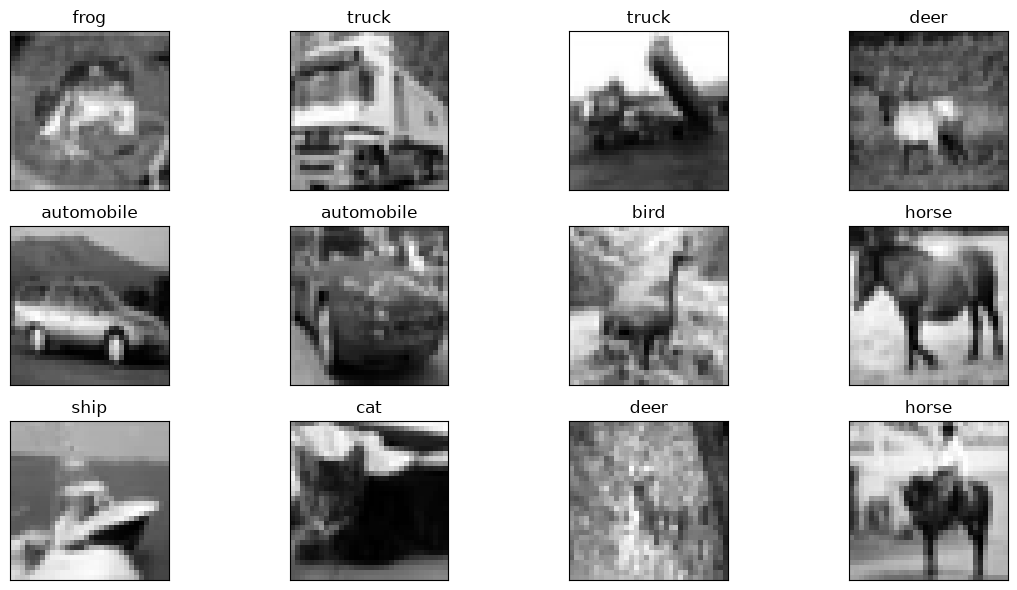

In [6]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [7]:
# TODO 2: Completa la arquitectura
model = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,490 (517.54 KB)

 Trainable params: 132,490 (517.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Validación TODO 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** `Dense` recibe un vector por ejemplo, no una matriz. `Flatten()` convierte cada imagen (32, 32) en un vector de 1024 valores para multiplicarlo por la matriz de pesos de la capa densa.**3.** ¿Por qué la última capa tiene 10 neuronas?

**Respuesta:** Porque hay 10 clases (airplane, automobile, ..., truck) y se usa una salida (un logit) por clase.**4.** ¿Qué función cumple `ReLU`?

**Respuesta:** Introduce la no linealidad, $\max(0,x)$. Sin ella, `Dense(128)` seguida de `Dense(10)` equivaldría a una sola transformación lineal (una regresión logística) y la capa oculta no aportaría nada.

---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [9]:
lr_rate = 0.001

# TODO 3: Configura el entrenamiento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

### Pregunta 5

¿Por qué usamos `from_logits=True`?

**Respuesta:** Porque la última capa produce logits, no probabilidades. Con `from_logits=True` la pérdida aplica la softmax internamente junto con el logaritmo de forma numéricamente estable; por eso no se añade `Softmax` al modelo.

---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [10]:
epochs = 10
batch_size = 64

# TODO 4: Entrenamiento
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)

Epoch 1/10


  1/782 ━━━━━━━━━━━━━━━━━━━━ 2:37 202ms/step - accuracy: 0.0938 - loss: 2.4658

 90/782 ━━━━━━━━━━━━━━━━━━━━ 0s 564us/step - accuracy: 0.1677 - loss: 2.2161  

182/782 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step - accuracy: 0.1947 - loss: 2.1650

275/782 ━━━━━━━━━━━━━━━━━━━━ 0s 549us/step - accuracy: 0.2081 - loss: 2.1439

...

464/782 ━━━━━━━━━━━━━━━━━━━━ 0s 543us/step - accuracy: 0.3817 - loss: 1.7556

557/782 ━━━━━━━━━━━━━━━━━━━━ 0s 543us/step - accuracy: 0.3798 - loss: 1.7567

650/782 ━━━━━━━━━━━━━━━━━━━━ 0s 543us/step - accuracy: 0.3811 - loss: 1.7540

742/782 ━━━━━━━━━━━━━━━━━━━━ 0s 544us/step - accuracy: 0.3834 - loss: 1.7474

782/782 ━━━━━━━━━━━━━━━━━━━━ 0s 618us/step - accuracy: 0.3831 - loss: 1.7472 - val_accuracy: 0.3630 - val_loss: 1.7775


### Preguntas

**6.** ¿Qué representa una `epoch`?

**Respuesta:** Una pasada completa por los 50,000 ejemplos de entrenamiento. Se hicieron 10.**7.** ¿Qué representa `batch_size=64`?

**Respuesta:** Cada actualización de pesos usa 64 imágenes, así que una época son 782 actualizaciones (50,000 / 64, redondeado hacia arriba), que es lo que muestra la barra `782/782`.

## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


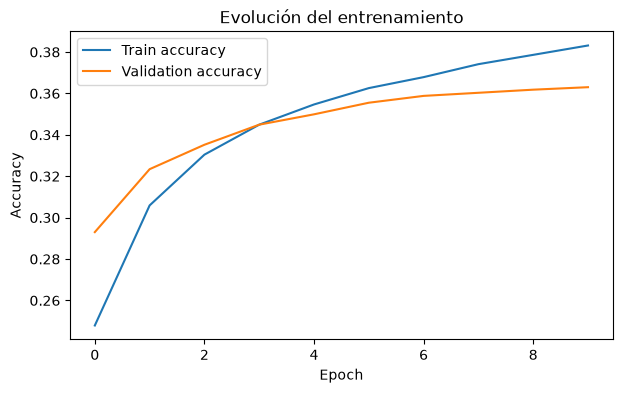

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ¿Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** **No hay evidencia clara de overfitting; si algo, hay subajuste.** Al final del entrenamiento el accuracy es 38.3% en entrenamiento (promedio móvil de la época) y 36.3% en validación: una brecha de apenas 2 puntos, con ambas curvas subiendo despacio. La validación casi se aplana (35.9% en la época 6, 36.3% en la 10). Una brecha pequeña con accuracy bajo es el patrón de un modelo que no tiene capacidad o estructura suficiente para el problema, no de uno que memoriza.

---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [12]:
# TODO 5: Evaluación
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

Test loss     : 1.7775
Test accuracy : 0.3630
Accuracy (%)  : 36.30%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

¿CIFAR-10 en escala de grises parece más fácil o más difícil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** **Mucho más difícil.** En Fashion-MNIST, con la misma idea (red `Flatten → Dense(128) → Dense(10)`), el notebook de clase obtuvo 87.9% en prueba en la ejecución hecha para este solucionario; aquí se obtiene **36.30%**, unos 51 puntos menos, aunque el azar con 10 clases sea 10%. La razón: Fashion-MNIST son siluetas centradas sobre fondo uniforme, mientras que CIFAR-10 trae objetos en cualquier posición, escala y fondo, y en grises se pierde además el color, que ayudaba a separar clases (cielo azul, pasto verde).

---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


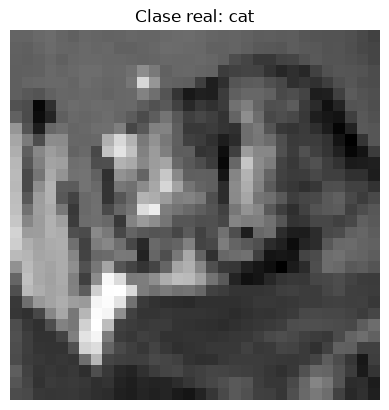

Logits:
[[ 0.91277087 -1.5765182   1.572216    0.31313083  1.0622674   0.2838921
   0.5608783   0.4730686  -0.2837162  -1.977528  ]]


In [13]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [14]:
# TODO 6: Logits -> probabilidades
probabilities = keras.ops.softmax(logits)

# TODO 7: Clase con mayor probabilidad
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print("Clase real     :", class_names[true_class])
print("Clase predicha :", class_names[prediction])

Clase real     : cat
Clase predicha : bird


In [15]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.1436
automobile  : 0.0119
bird        : 0.2776 ← predicción
cat         : 0.0788
deer        : 0.1667
dog         : 0.0765
frog        : 0.1010
horse       : 0.0925
ship        : 0.0434
truck       : 0.0080

Suma: 1.0000001


### Pregunta 10

¿Por qué las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Porque Softmax divide cada $e^{z_k}$ entre la suma de todos los $e^{z_j}$: las probabilidades son positivas y por construcción suman 1. La salida lo confirma: `Suma: 1.0000001` (el exceso es error de redondeo de `float32`). Para la imagen de ejemplo la mayor probabilidad es solo 0.2776 (bird, y la real era cat): el modelo está poco seguro.

---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


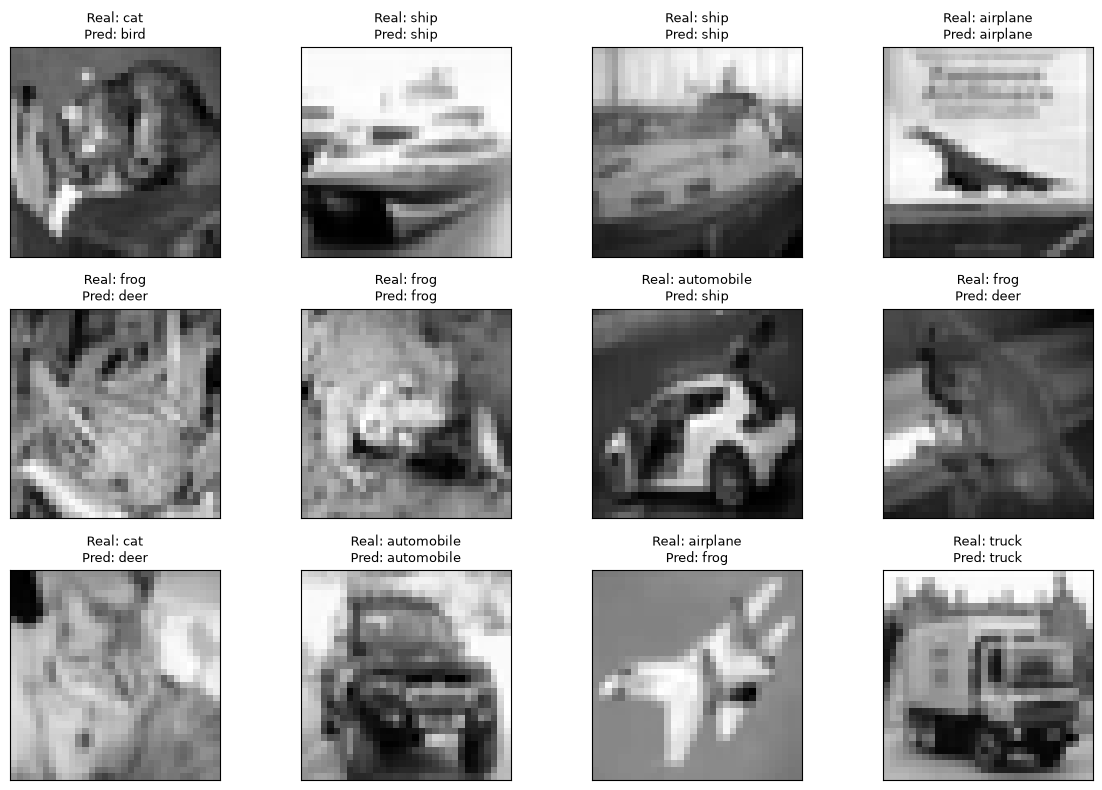

In [16]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 8. Reflexión final

### 1. ¿Cuál fue el accuracy final?

**Respuesta:** **36.30%** en prueba (pérdida 1.7775), con 10 épocas y batch de 64 como pide el enunciado. Es 3.6 veces el azar (10%) pero muy por debajo de Fashion-MNIST.### 2. ¿Qué clases parecen más difíciles de distinguir?

**Respuesta:** Las más difíciles: `cat` (19.2%), `dog` (28.4%) y `frog` (30.3%). Las más fáciles: `ship` (57.6%), `airplane` (43.3%) y `automobile` (40.7%). Las confusiones más frecuentes son automobile, airplane y truck clasificados como ship (193, 191 y 180 veces), y bird y deer entre sí (172 y 167). Parecen tener que ver con fondos y siluetas parecidas más que con los objetos, algo que esta red no puede distinguir bien; es una interpretación, no se midió qué usa la red.### 3. Después de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ¿Qué información importante sobre la imagen podría perderse al tratarla únicamente como un vector?

**Respuesta:** Se pierde la vecindad espacial: el píxel (i, j) y su vecino (i, j+1) pasan a ser dos posiciones sin relación en el vector. Se pierden también bordes, texturas y formas locales, y la invarianza a traslaciones: un gato desplazado unos píxeles produce un vector casi sin parecido con el original.### 4. ¿Qué tipo de arquitectura podría aprovechar mejor la estructura espacial de las imágenes?

**Respuesta:** Una red convolucional (CNN): comparte los mismos filtros en toda la imagen, aprovecha que los píxeles cercanos están relacionados, detecta bordes y formas locales en cualquier posición y usa muchos menos parámetros por capa que una `Dense` sobre todos los píxeles. No se entrenó una aquí; es lo que anticipa el enunciado.---

## Para pensar

Nuestro modelo hace:

```text
32×32 → Flatten → 1024 valores → Dense → ReLU → Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **¿Cómo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta será: **Convolutional Neural Networks (CNNs)**.


## Apoyo para la reflexión: exactitud por clase

Para responder con datos qué clases son más difíciles (pregunta 2 de la reflexión), se calcula la exactitud de cada clase sobre las 10 000 imágenes de prueba y las confusiones más frecuentes. Esta celda no está en el enunciado original; es un añadido para no responder de memoria.

In [17]:
from sklearn.metrics import confusion_matrix

pred_all = keras.ops.convert_to_numpy(keras.ops.argmax(model.predict(X_test, batch_size=256, verbose=0), axis=1))
cm = confusion_matrix(y_test, pred_all)
acc_clase = cm.diagonal() / cm.sum(axis=1)

print("Exactitud por clase (de mayor a menor):")
for i in np.argsort(-acc_clase):
    print(f"  {class_names[i]:12s} {acc_clase[i]*100:5.1f}%")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nConfusiones más frecuentes (real -> predicha):")
for idx in np.argsort(-off, axis=None)[:6]:
    a, b = divmod(idx, 10)
    print(f"  {class_names[a]:12s} -> {class_names[b]:12s} {off[a, b]} veces")

print(f"\nGap train-test final: train {history.history['accuracy'][-1]:.4f} vs val {history.history['val_accuracy'][-1]:.4f}")

Exactitud por clase (de mayor a menor):
  ship          57.6%
  airplane      43.3%
  automobile    40.7%
  horse         38.8%
  truck         38.5%
  deer          34.6%
  bird          31.6%
  frog          30.3%
  dog           28.4%
  cat           19.2%

Confusiones más frecuentes (real -> predicha):
  automobile   -> ship         193 veces
  airplane     -> ship         191 veces
  truck        -> ship         180 veces
  truck        -> automobile   174 veces
  bird         -> deer         172 veces
  deer         -> bird         167 veces

Gap train-test final: train 0.3831 vs val 0.3630
